# Video Game Sales Prediction on Steam Data
## Notebook 10 — Modification 7: Forecasting from the Predecessor

**Third paper.** Schaer, O., Kourentzes, N. & Fildes, R. (2026). *Analogy-based life cycle forecasts with
pre-release buzz.* European Journal of Operational Research, 333, 88–100. DOI 10.1016/j.ejor.2025.12.003.

The paper forecasts the sales of a new video game before launch from an **analogy**: the previous game of the
same franchise. It uses weekly sales of 251 games in 57 franchises (VGChartz) and Google search interest before
release. Its benchmark is that the new game sells what its predecessor sold. Its best model multiplies the
predecessor's sales by the square root of the change in pre-release search interest, and beats the benchmark by
17% for first-week sales and 21% for lifetime sales. Two of its findings matter here: a game's own history is
a strong forecast by itself, and the simplest models outperform those with more estimated parameters.

**Why this paper.** Notebooks 5–9 predicted owners from what a game *is*: its store page, studio experience and
lead time. One year ahead that reaches R² (log) of about 0.25. The only variables that clearly helped on later
releases were a studio's past sales (Notebook 7, E10), which were set aside. The paper makes past sales the
centre of the method.

**What is borrowed and what is not.**

| | Paper | This notebook |
|---|---|---|
| Analogy | Previous game of the same franchise | **Borrowed**, and widened: series predecessor, otherwise the developer's previous game, otherwise the publisher's |
| Benchmark | New game = predecessor's sales | **Borrowed** (E17) |
| Buzz measure | Google search interest before release | **Not available.** Store-page lead time is tried in its place |
| Model | Predecessor's sales × √(change in buzz) | Tried with lead time (E17); predecessor variables are also added to the Gradient Boosting model (E18) |
| Sample | 251 games from 57 popular franchises | All 76,727 games; about half have no predecessor |
| Outcome | Weekly sales over 52 weeks | Lifetime owners in ranges, as counted in 2025 |
| Accuracy measure | Error relative to the benchmark (geometric mean) | Mean absolute error relative to the benchmark; the geometric mean cannot be used because the benchmark's error is exactly zero whenever a game lands in its predecessor's owner range |

**A limitation carried over from Notebook 7.** A predecessor's owner count is the 2025 snapshot. It includes
copies sold after the new game came out, which a forecaster at the time could not have known. Section 15.5
tests how much the results depend on this.

**Rules.**
- **Protocol:** random folds and the one-year-ahead evaluation of Notebooks 8 and 9 (each of 2022, 2023 and
  2024 predicted from all earlier games, mean of five seeds). The test set is used once per model.
- **Adoption:** a gain of at least 0.01 in R² (log) with random folds that also holds one year ahead.

**Questions.**
1. How closely does a game follow its predecessor?
2. Does the paper's benchmark, the predecessor's owners alone, compete with the store-page model?
3. Does adding the predecessor to the model improve forecasts of later releases, and for which games?

The same experiments are recorded as E17–E19 in `experiments/EXPERIMENT_LOG.md`.

In [1]:
import json
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42
SEEDS = [42, 1, 2, 3, 4]

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
with open(os.path.join(DATA_DIR, "engineered_features.json")) as f:
    groups = json.load(f)
engineered = pd.read_csv(os.path.join(DATA_DIR, "engineered_features.csv.gz"))   # written by Notebook 7
data = data.merge(engineered, on="appid", how="left", validate="one_to_one")     # keeps the row order of Notebook 1

FEATURES = spec["numeric"] + spec["genres"] + spec["categories"] \
    + groups["A. Studio experience"] + groups["C. Store-page lead time"]          # the 49 variables of Notebook 7
STUDIO_AVERAGES = groups["Past sales (sensitivity only)"]                         # the four variables of E10
data["owners"] = (data["owners_millions"] * 1e6).round()
data["log_owners"] = np.log1p(data["owners"])
data["breakout"] = (data["owners"] > 10_000).astype(int)
print(f"{len(data):,} games, {len(FEATURES)} variables in the reference model")

C:\Users\Nobutaka\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


76,727 games, 49 variables in the reference model


---
# 15. Modification 7: Forecasting from the Predecessor

## 15.1 Finding each game's predecessor

For every game, three earlier games are looked up among the games of this study:
- the **series predecessor**: the most recent earlier game with the same title stem (Notebook 7, Section 12.1)
  from the same developer or publisher;
- the **developer's previous game**;
- the **publisher's previous game**.

Only games released strictly before the game in question count. For each, the predecessor's log owners and the
gap between the two release dates are kept, which gives six variables. One game is also chosen as *the*
analogy, in the order above, for the paper's benchmark.

In [2]:
# Developer and publisher names are not in the modeling table; they are read from the raw file (version 49)
path = kagglehub.dataset_download("fronkongames/steam-games-dataset/versions/49")
with open(os.path.join(path, "games.json"), encoding="utf-8") as f:
    raw_json = json.load(f)
in_table = set(data["appid"])
names = pd.DataFrame([{"appid": int(appid), "developer": (v.get("developers") or [None])[0],
                       "publisher": (v.get("publishers") or [None])[0]}
                      for appid, v in raw_json.items() if int(appid) in in_table])
del raw_json
data = data.merge(names, on="appid", how="left", validate="one_to_one")

# Title stem as in Notebook 7: the part before a subtitle, without a trailing number
NUMERAL = r"(?:[2-9]|1[0-9]|II|III|IV|V|VI|VII|VIII|IX|X)"
stem = data["name"].fillna("").str.split(r":|\s-\s", regex=True).str[0]
stem = stem.str.replace(rf"\s+(?:[0-9]+|{NUMERAL})\s*$", "", regex=True).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
stem = stem.where(stem.str.len() >= 4)
for key, owner in [("series_dev", "developer"), ("series_pub", "publisher")]:
    data[key] = np.where(stem.notna() & data[owner].notna(), stem.astype(str) + "|" + data[owner].astype(str), None)


def previous_game(key, min_gap_years=0):
    """For every game: the most recent game with the same key released earlier (by at least `min_gap_years`).
    Returns its AppID, its log owners and the gap between the two release dates in years."""
    games = data.dropna(subset=[key])[["appid", key, "release_dt", "log_owners"]].sort_values("release_dt")
    earlier = games.rename(columns={"appid": "prev_appid", "log_owners": "prev_log_owners"}).assign(prev_dt=games["release_dt"])
    later = games[["appid", key, "release_dt"]].copy()
    later["release_dt"] = later["release_dt"] - pd.Timedelta(days=round(365.25 * min_gap_years))
    # allow_exact_matches=False: the earlier game must be released strictly before the (shifted) date
    m = pd.merge_asof(later, earlier[[key, "release_dt", "prev_appid", "prev_log_owners", "prev_dt"]],
                      on="release_dt", by=key, allow_exact_matches=False)
    m["gap_years"] = (m["release_dt"] - m["prev_dt"]).dt.days / 365.25 + min_gap_years
    return data[["appid"]].merge(m[["appid", "prev_appid", "prev_log_owners", "gap_years"]], on="appid", how="left")


def predecessors(min_gap_years=0):
    """Predecessor variables for every game, and one 'analogy': the series predecessor if there is one,
    otherwise the developer's previous game, otherwise the publisher's previous game."""
    by_dev, by_pub = previous_game("series_dev", min_gap_years), previous_game("series_pub", min_gap_years)
    use_pub = by_dev["prev_appid"].isna() | (by_pub["gap_years"] < by_dev["gap_years"])
    series = by_dev.where(~use_pub, by_pub)
    developer, publisher = previous_game("developer", min_gap_years), previous_game("publisher", min_gap_years)
    out = pd.DataFrame({"appid": data["appid"]})
    for name, frame in [("series", series), ("dev", developer), ("pub", publisher)]:
        out[f"{name}_prev_log_owners"], out[f"{name}_gap_years"] = frame["prev_log_owners"], frame["gap_years"]
    chosen = series.where(series["prev_appid"].notna(), developer.where(developer["prev_appid"].notna(), publisher))
    out["analogy_appid"], out["analogy_log_owners"] = chosen["prev_appid"], chosen["prev_log_owners"]
    out["analogy_type"] = np.select([series["prev_appid"].notna(), developer["prev_appid"].notna(),
                                     publisher["prev_appid"].notna()],
                                    ["Series predecessor", "Developer's previous game", "Publisher's previous game"],
                                    "No predecessor")
    return out


PREDECESSOR = ["series_prev_log_owners", "series_gap_years", "dev_prev_log_owners", "dev_gap_years",
               "pub_prev_log_owners", "pub_gap_years"]
by_gap = {gap: predecessors(gap) for gap in (0, 1, 2, 3)}
data = data.merge(by_gap[0], on="appid", how="left", validate="one_to_one")
by_gap[0].to_csv(os.path.join(DATA_DIR, "predecessor_features.csv.gz"), index=False)
for gap in (1, 2, 3):
    by_gap[gap].to_csv(os.path.join(DATA_DIR, f"predecessor_features_gap{gap}.csv.gz"), index=False)

TYPES = ["Series predecessor", "Developer's previous game", "Publisher's previous game", "No predecessor"]
by_type = data.groupby("analogy_type")
same_range = data.assign(same=np.isclose(data["log_owners"], data["analogy_log_owners"])).groupby("analogy_type")["same"].mean()
table48 = pd.DataFrame({
    "Games": by_type.size(), "Share of all games": by_type.size() / len(data),
    "Share in the breakout group": by_type["breakout"].mean(),
    "Correlation with the predecessor (log owners)": by_type.apply(lambda g: g["log_owners"].corr(g["analogy_log_owners"])),
    "Same owner range as the predecessor": same_range,
}).reindex(TYPES)
table48.loc["No predecessor", ["Correlation with the predecessor (log owners)", "Same owner range as the predecessor"]] = np.nan
table48.index.name = "Analogy used"
table48.to_csv(os.path.join(TAB_DIR, "table48_predecessor_coverage.csv"))
table48.style.format({"Games": "{:,}", "Share of all games": "{:.1%}", "Share in the breakout group": "{:.1%}",
                      "Correlation with the predecessor (log owners)": "{:.2f}",
                      "Same owner range as the predecessor": "{:.1%}"}, na_rep="").set_caption(
    "Table 48. Games by the kind of predecessor available")

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\2381416921.py:68: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Correlation with the predecessor (log owners)": by_type.apply(lambda g: g["log_owners"].corr(g["analogy_log_owners"])),


,Games,Share of all games,Share in the breakout group,Correlation with the predecessor (log owners),Same owner range as the predecessor
Analogy used,,,,,
Series predecessor,"5,284",6.9%,37.2%,0.78,60.0%
Developer's previous game,"25,349",33.0%,31.5%,0.56,59.4%
Publisher's previous game,"6,377",8.3%,50.1%,0.51,41.9%
No predecessor,"39,717",51.8%,25.5%,,


**Interpretation.**
- **About half of all games have a predecessor.** 6.9% continue a series, 33.0% have an earlier game by the same
  developer, and 8.3% have only an earlier game by the same publisher. The remaining 51.8% are a studio's first
  game in the data.
- **A series predecessor is the closest analogy.** Its log owners correlate 0.78 with the new game's, against
  0.56 for the developer's previous game and 0.51 for the publisher's.
- **Six in ten games land in the same owner range as their predecessor** when it is a series predecessor (60.0%)
  or the developer's previous game (59.4%).

## 15.2 How closely a game follows its predecessor

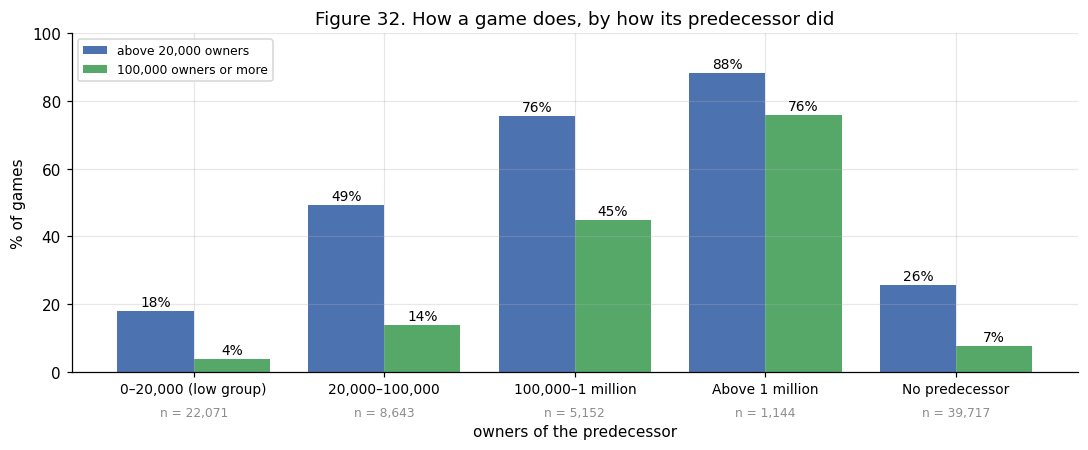

,Games,Median owners,"Share above 20,000 owners","Share with 100,000 owners or more"
Predecessor's owners,,,,
"0–20,000 (low group)","22,071","10,000",18.0%,3.8%
"20,000–100,000","8,643","10,000",49.3%,13.9%
"100,000–1 million","5,152","75,000",75.6%,44.8%
Above 1 million,"1,144","350,000",88.3%,75.8%
No predecessor,"39,717","10,000",25.5%,7.5%


In [3]:
with_analogy = data[data["analogy_type"] != "No predecessor"].copy()
PREV_LABELS = ["0–20,000 (low group)", "20,000–100,000", "100,000–1 million", "Above 1 million"]
with_analogy["Predecessor's owners"] = pd.cut(np.expm1(with_analogy["analogy_log_owners"]),
                                              [0, 15_000, 80_000, 800_000, np.inf], labels=PREV_LABELS)
g = with_analogy.groupby("Predecessor's owners", observed=True)
table49 = pd.DataFrame({"Games": g.size(), "Median owners": g["owners"].median(),
                        "Share above 20,000 owners": g["breakout"].mean(),
                        "Share with 100,000 owners or more": g["owners"].apply(lambda s: (s >= 100_000).mean())})
none = data[data["analogy_type"] == "No predecessor"]
table49.loc["No predecessor"] = [len(none), none["owners"].median(), none["breakout"].mean(), (none["owners"] >= 100_000).mean()]
table49.to_csv(os.path.join(TAB_DIR, "table49_owners_by_predecessor.csv"))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(table49))
ax.bar(x - 0.2, 100 * table49["Share above 20,000 owners"], 0.4, color=BLUE, label="above 20,000 owners")
ax.bar(x + 0.2, 100 * table49["Share with 100,000 owners or more"], 0.4, color=GREEN, label="100,000 owners or more")
for xi, a, b, n in zip(x, table49["Share above 20,000 owners"], table49["Share with 100,000 owners or more"], table49["Games"]):
    ax.text(xi - 0.2, 100 * a + 1.5, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(xi + 0.2, 100 * b + 1.5, f"{b:.0%}", ha="center", fontsize=9)
    ax.text(xi, -13, f"n = {int(n):,}", ha="center", fontsize=8, color=GREY)
ax.set_xticks(x)
ax.set_xticklabels(table49.index, fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel("% of games")
ax.set_xlabel("owners of the predecessor", labelpad=18)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Figure 32. How a game does, by how its predecessor did")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig32_owners_by_predecessor.png"), dpi=150, bbox_inches="tight")
plt.show()
table49.style.format({"Games": "{:,.0f}", "Median owners": "{:,.0f}", "Share above 20,000 owners": "{:.1%}",
                      "Share with 100,000 owners or more": "{:.1%}"}).set_caption(
    "Table 49. Owners of a game by the owners of its predecessor")

**Interpretation.**
- **The predecessor's result sorts games strongly.** When the predecessor stayed in the low group, 18.0% of
  games rise above 20,000 owners. When it had 20,000–100,000 owners the share is 49.4%; with 100,000 to 1
  million, 75.6%; and above 1 million, 88.3%.
- **The same holds for larger successes.** 3.8% of games reach 100,000 owners after a low-group predecessor,
  against 75.8% after a predecessor with more than 1 million.
- **Games without a predecessor sit near the overall average** (25.5% above 20,000 owners).
- No store-page variable in Notebook 9 separated the groups this clearly; the largest difference there was
  0.37 standard deviations.

## 15.3 The paper's benchmark: the predecessor alone (E17)

Three forecasts that use no model fitted on store-page variables are compared with the reference model of
Notebook 7, one year ahead and only on games that have a predecessor:
- **the paper's benchmark:** the new game gets its predecessor's owners;
- **the benchmark adjusted for release year:** the predecessor's owners are moved from the average level of its
  own release year to that of the last known year, because older games have had longer to sell (Notebook 8);
- **the paper's best model with lead time in place of search interest:** predecessor's owners × the square root
  of the ratio of the two store-page lead times.

As in the paper, each forecast is also expressed relative to the benchmark: a value above 1 means a larger mean
absolute error than the benchmark.

In [4]:
train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))
AHEAD_YEARS = (2022, 2023, 2024)


def gb(seed=RANDOM_STATE):
    return HistGradientBoostingRegressor(random_state=seed)


def scores(frame, pred):
    y = frame["log_owners"].to_numpy()
    return {"R² (log)": r2_score(y, pred), "MAE (log)": mean_absolute_error(y, pred), "Bias (log)": float(np.mean(pred - y))}


def one_year_ahead(features, frame=None, seeds=SEEDS):
    """Each of 2022, 2023 and 2024 predicted by a model fitted on all earlier training-set games.
    Returns one row per scored game and seed, with the prediction."""
    frame = train if frame is None else frame
    parts = []
    for year in AHEAD_YEARS:
        earlier, target = frame[frame["release_year"] < year], frame[frame["release_year"] == year]
        for seed in seeds:
            pred = gb(seed).fit(earlier[features], earlier["log_owners"]).predict(target[features])
            parts.append(target[["appid", "release_year", "log_owners", "breakout", "analogy_type"]].assign(seed=seed, pred=pred))
    return pd.concat(parts, ignore_index=True)


def ahead_summary(predictions, mask=None):
    """Scores per year and seed, then averaged (as in Notebooks 8 and 9)."""
    p = predictions if mask is None else predictions[mask]
    return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


def random_fold_r2(features, frame=None):
    frame = train if frame is None else frame
    oof = np.zeros(len(frame))
    for tr, va in folds:
        oof[va] = gb().fit(frame.iloc[tr][features], frame["log_owners"].to_numpy()[tr]).predict(frame.iloc[va][features])
    return r2_score(frame["log_owners"], oof), oof

In [5]:
lead_by_appid = data.set_index("appid")["log_lead_days"]
year_by_appid = data.set_index("appid")["release_year"]
reference_ahead = one_year_ahead(FEATURES, seeds=[RANDOM_STATE])

rows = []
for subset, types in [("Series predecessor", ["Series predecessor"]),
                      ("Any predecessor", TYPES[:3])]:
    per_year = {name: [] for name in ["Predecessor's owners (the paper's benchmark)",
                                      "Predecessor's owners, adjusted for release year",
                                      "Predecessor's owners × √(change in lead time)",
                                      "Reference model (49 store-page variables)"]}
    for year in AHEAD_YEARS:
        earlier = train[train["release_year"] < year]
        target = train[(train["release_year"] == year) & train["analogy_type"].isin(types)]
        naive = target["analogy_log_owners"].to_numpy()
        # release-year adjustment: move the predecessor from the level of its own year to the last known year
        year_mean = earlier.groupby("release_year")["log_owners"].mean()
        prev_year = target["analogy_appid"].map(year_by_appid)
        adjusted = naive - prev_year.map(year_mean).fillna(year_mean.iloc[-1]).to_numpy() + year_mean.iloc[-1]
        # the paper's best model (M.6) with lead time in place of search traffic
        lead_change = target["log_lead_days"].to_numpy() - target["analogy_appid"].map(lead_by_appid).to_numpy()
        reference = reference_ahead.set_index("appid").loc[target["appid"], "pred"].to_numpy()
        for name, pred in zip(per_year, [naive, adjusted, naive + 0.5 * lead_change, reference]):
            per_year[name].append({"Games": len(target), **scores(target, pred)})
    for name, values in per_year.items():
        v = pd.DataFrame(values)
        rows.append({"Games scored": subset, "Forecast": name, "Games per year": v["Games"].mean(),
                     "R² (log)": v["R² (log)"].mean(), "MAE (log)": v["MAE (log)"].mean(), "Bias (log)": v["Bias (log)"].mean()})
table50 = pd.DataFrame(rows).set_index(["Games scored", "Forecast"])
benchmark_mae = table50.groupby(level=0)["MAE (log)"].transform("first")
table50["MAE relative to the benchmark"] = table50["MAE (log)"] / benchmark_mae
table50.to_csv(os.path.join(TAB_DIR, "table50_predecessor_benchmark.csv"))
table50.style.format({"Games per year": "{:,.0f}", "R² (log)": "{:.3f}", "MAE (log)": "{:.3f}", "Bias (log)": "{:+.3f}",
                      "MAE relative to the benchmark": "{:.2f}"}).set_caption(
    "Table 50. Forecasting a game from its predecessor alone (E17; one year ahead, mean of 2022–2024)")

**Interpretation.**
- **On absolute error, the predecessor alone beats the store-page model.** For games with a series predecessor,
  the benchmark's MAE (log) is 0.502 and the reference model's is 0.552, 10% larger. For all games with any
  predecessor it is 0.588 against 0.614, 4% larger. One number, the predecessor's owners, does better on this
  measure than 49 store-page variables.
- **On R² the store-page model is far ahead** (0.459 against 0.160 for series games; 0.332 against −0.138 for
  any predecessor). The benchmark is exactly right for the six in ten games that stay in their predecessor's
  range, but badly wrong for the rest, and R² punishes large misses.
- **The two forecasts are therefore complementary:** the predecessor fixes the level of a game, and the
  store-page variables adjust it. This is the case for combining them (Section 15.4).
- **The release-year adjustment removes about half of the benchmark's over-prediction** for series games (bias
  +0.20 → +0.09) and raises R² slightly (0.160 → 0.191).
- **Lead time cannot stand in for search interest in the paper's formula.** Scaling the predecessor's owners by
  the change in lead time roughly doubles the error (relative MAE 1.97 and 1.78). Lead time measures how long a
  page existed, not how many people looked for the game. The paper's buzz model is not reproduced here.

## 15.4 The predecessor in the model (E18, E19)

The paper keeps its models very small because a publisher has only a few games per franchise. With 61,381
training games, the predecessor can instead be given to the Gradient Boosting model as additional variables,
so that store-page information and the game's history are used together. Missing predecessors are left
missing, which Gradient Boosting handles directly.
- **E18** adds the six predecessor variables of Section 15.1.
- **E19** also adds the four studio averages of Notebook 7 (E10): the mean and the best log owners over all
  earlier games of the developer and of the publisher.

In [6]:
THRESHOLD = 0.01
SETS = [("Reference (Notebook 7)", "49 store-page variables", FEATURES),
        ("E18", "+ predecessor's owners and release gap (6 variables)", FEATURES + PREDECESSOR),
        ("E19", "+ studio averages of E10 (4 variables)", FEATURES + PREDECESSOR + STUDIO_AVERAGES)]
ahead, oof, rows = {}, {}, []
for exp_id, change, features in SETS:
    r2_random, oof[exp_id] = random_fold_r2(features)
    ahead[exp_id] = one_year_ahead(features)
    a = ahead_summary(ahead[exp_id])
    rows.append({"Experiment": exp_id, "Variables": change, "Number of variables": len(features),
                 "Random folds: R² (log)": r2_random, "One year ahead: R² (log)": a["R² (log)"],
                 "One year ahead: MAE (log)": a["MAE (log)"], "One year ahead: bias (log)": a["Bias (log)"]})
table51 = pd.DataFrame(rows).set_index("Experiment")
for column in ["Random folds: R² (log)", "One year ahead: R² (log)"]:
    table51[column.replace("R² (log)", "gain")] = table51[column].diff()
table51 = table51[["Variables", "Number of variables", "Random folds: R² (log)", "Random folds: gain",
                   "One year ahead: R² (log)", "One year ahead: gain", "One year ahead: MAE (log)",
                   "One year ahead: bias (log)"]]
table51.to_csv(os.path.join(TAB_DIR, "table51_predecessor_models.csv"))
table51.style.format({"Random folds: R² (log)": "{:.3f}", "Random folds: gain": "{:+.3f}", "One year ahead: R² (log)": "{:.3f}",
                      "One year ahead: gain": "{:+.3f}", "One year ahead: MAE (log)": "{:.3f}",
                      "One year ahead: bias (log)": "{:+.3f}"}, na_rep="").set_caption(
    "Table 51. Adding the predecessor to the model (one year ahead: mean of 2022–2024 and five seeds; "
    "each gain is over the row above)")

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


,Variables,Number of variables,Random folds: R² (log),Random folds: gain,One year ahead: R² (log),One year ahead: gain,One year ahead: MAE (log),One year ahead: bias (log)
Experiment,,,,,,,,
Reference (Notebook 7),49 store-page variables,49,0.460,,0.250,,0.556,+0.113
E18,+ predecessor's owners and release gap (6 variables),55,0.490,+0.030,0.292,+0.041,0.531,+0.101
E19,+ studio averages of E10 (4 variables),59,0.502,+0.011,0.311,+0.020,0.522,+0.097


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()
C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()
C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()
C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()
C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


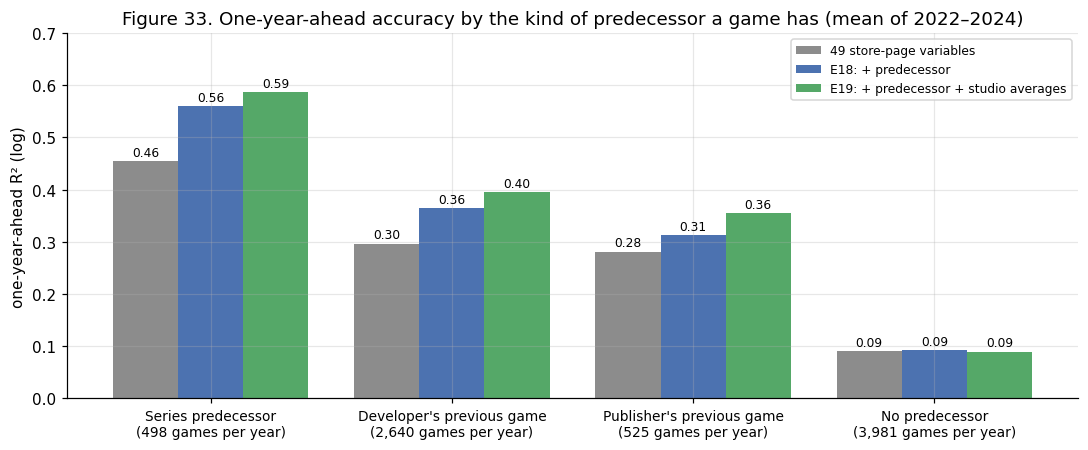

,Games per year,Reference (Notebook 7),E18,E19
Analogy available,,,,
Series predecessor,498,0.455,0.560,0.588
Developer's previous game,"2,640",0.296,0.364,0.395
Publisher's previous game,525,0.281,0.313,0.355
No predecessor,"3,981",0.090,0.092,0.089


In [7]:
rows = []
for kind in TYPES:
    row = {"Analogy available": kind,
           "Games per year": (ahead["E18"]["analogy_type"] == kind).sum() / len(SEEDS) / len(AHEAD_YEARS)}
    for exp_id, _, _ in SETS:
        row[exp_id] = ahead_summary(ahead[exp_id], ahead[exp_id]["analogy_type"] == kind)["R² (log)"]
    rows.append(row)
table52 = pd.DataFrame(rows).set_index("Analogy available")
table52.to_csv(os.path.join(TAB_DIR, "table52_predecessor_by_subset.csv"))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(TYPES))
for i, (exp_id, color) in enumerate(zip(["Reference (Notebook 7)", "E18", "E19"], [GREY, BLUE, GREEN])):
    ax.bar(x + (i - 1) * 0.27, table52[exp_id], 0.27, color=color,
           label={"Reference (Notebook 7)": "49 store-page variables", "E18": "E18: + predecessor",
                  "E19": "E19: + predecessor + studio averages"}[exp_id])
    for xi, v in zip(x + (i - 1) * 0.27, table52[exp_id]):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{t}\n({n:,.0f} games per year)" for t, n in zip(TYPES, table52["Games per year"])], fontsize=9)
ax.set_ylim(0, 0.7)
ax.set_ylabel("one-year-ahead R² (log)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Figure 33. One-year-ahead accuracy by the kind of predecessor a game has (mean of 2022–2024)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig33_predecessor_by_subset.png"), dpi=150, bbox_inches="tight")
plt.show()
table52.style.format({"Games per year": "{:,.0f}", **{e: "{:.3f}" for e, _, _ in SETS}}).set_caption(
    "Table 52. One-year-ahead R² (log) by the kind of predecessor available (mean of 2022–2024 and five seeds)")

**Interpretation.**
- **The predecessor is the first change that clearly improves forecasts of later releases (E18).** One year
  ahead, R² (log) rises from 0.250 to 0.292 (+0.041), and with random folds from 0.460 to 0.490 (+0.030). Both
  pass the adoption rule. For comparison, the two variable groups adopted in Notebook 7 added +0.023 with
  random folds and almost nothing on later releases.
- **The studio averages add a further gain (E19):** +0.011 with random folds and +0.020 one year ahead, to
  0.502 and 0.311. The most recent game and the whole track record carry partly different information.
- **The gain is concentrated where a predecessor exists (Table 52, Figure 33).** From the reference model to
  E19, one-year-ahead R² rises from 0.455 to 0.588 for games with a series predecessor, from 0.296 to 0.396
  for games with a developer's previous game, and from 0.281 to 0.355 for games with only a publisher's.
- **Games without a predecessor are barely predictable, and nothing here changes that.** Their one-year-ahead
  R² is 0.09 with every model. They are 52% of the games scored. The overall figure of about 0.25 in Notebooks
  8 and 9 was an average of two very different groups: games with a history (about 0.30 to 0.46) and games
  without one (0.09).

## 15.5 Does the result depend on the 2025 snapshot?

A predecessor's owner count includes copies sold after the new game was released. The concern is largest for a
predecessor released shortly before the new game, because most of its sales were still to come. If the gain of
E18 came mainly from that, it should shrink quickly once such predecessors are excluded. E18 is therefore
repeated with predecessors that were released at least one, two or three years before the new game.

In [8]:
rows = []
for gap in (0, 1, 2, 3):
    frame = train.drop(columns=by_gap[0].columns.drop("appid")).merge(by_gap[gap], on="appid", how="left")
    a = ahead_summary(one_year_ahead(FEATURES + PREDECESSOR, frame))
    r2_random, _ = random_fold_r2(FEATURES + PREDECESSOR, frame)
    rows.append({"Predecessor released at least": "any time before" if gap == 0 else f"{gap} year{'s' if gap > 1 else ''} before",
                 "Games with a predecessor": (frame["analogy_type"] != "No predecessor").mean(),
                 "Random folds: R² (log)": r2_random, "One year ahead: R² (log)": a["R² (log)"],
                 "One year ahead: gain over the reference": a["R² (log)"] - table51.loc["Reference (Notebook 7)", "One year ahead: R² (log)"]})
table53 = pd.DataFrame(rows).set_index("Predecessor released at least")
table53.to_csv(os.path.join(TAB_DIR, "table53_predecessor_gap.csv"))
table53.style.format({"Games with a predecessor": "{:.1%}", "Random folds: R² (log)": "{:.3f}",
                      "One year ahead: R² (log)": "{:.3f}", "One year ahead: gain over the reference": "{:+.3f}"}).set_caption(
    "Table 53. E18 with predecessors restricted to games released well before the new game")

C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


C:\Users\Nobutaka\AppData\Local\Temp\ipykernel_16552\1607521112.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby(["release_year", "seed"]).apply(lambda g: pd.Series(scores(g, g["pred"]))).mean()


,Games with a predecessor,Random folds: R² (log),One year ahead: R² (log),One year ahead: gain over the reference
Predecessor released at least,,,,
any time before,48.2%,0.490,0.292,+0.041
1 year before,36.6%,0.478,0.286,+0.035
2 years before,28.0%,0.475,0.280,+0.030
3 years before,21.6%,0.471,0.274,+0.023


**Interpretation.**
- **The gain shrinks slowly, in step with the number of games that still have a predecessor.** With any earlier
  game allowed, 48.2% of games have a predecessor and the one-year-ahead gain is +0.041. Requiring one, two and
  three years between the releases leaves 36.6%, 28.1% and 21.6% of games with a predecessor and gains of
  +0.035, +0.030 and +0.024.
- **Per game covered, the gain does not fall.** Dividing each gain by the share of games with a predecessor
  gives 0.086, 0.096, 0.105 and 0.109. Predecessors that had already been on sale for years, whose owner counts
  were largely settled when the new game came out, are at least as informative as recent ones.
- **The result is therefore not mainly produced by the snapshot.** The limitation still stands: the exact
  owner count a forecaster would have seen at the time is unknown, and a successful sequel can also bring new
  buyers to the earlier game.

## 15.6 Test set and ranking

Each model is fitted once on the full training set and scored on the held-out test set. The one-year-ahead
predictions are also read as a ranking, as in Notebook 9: the share of games that rise above 20,000 owners
among the tenth of each year's games with the highest predicted owners.

In [9]:
def top_tenth(p):
    """Breakout share among the tenth of each year's games with the highest predicted owners."""
    out = []
    for (_, _), g in p.groupby(["release_year", "seed"]):
        k = int(round(0.1 * len(g)))
        out.append(g.nlargest(k, "pred")["breakout"].mean())
    return float(np.mean(out))


base_rate = train[train["release_year"].isin(AHEAD_YEARS)].groupby("release_year")["breakout"].mean().mean()
rows = []
for exp_id, change, features in SETS:
    fitted = gb().fit(train[features], train["log_owners"])
    test_scores = scores(test, fitted.predict(test[features]))                # the test set is used once per model
    precision = top_tenth(ahead[exp_id])
    rows.append({"Model": exp_id, "Test R² (log)": test_scores["R² (log)"], "Test MAE (log)": test_scores["MAE (log)"],
                 "One year ahead: breakout share in the top tenth": precision,
                 "One year ahead: lift over the base rate": precision / base_rate})
table54 = pd.DataFrame(rows).set_index("Model")
table54.to_csv(os.path.join(TAB_DIR, "table54_predecessor_test_and_ranking.csv"))
print(f"Mean base rate of 2022–2024: {base_rate:.1%} of games rise above 20,000 owners")
table54.style.format({"Test R² (log)": "{:.3f}", "Test MAE (log)": "{:.3f}",
                      "One year ahead: breakout share in the top tenth": "{:.1%}",
                      "One year ahead: lift over the base rate": "{:.1f}×"}).set_caption(
    f"Table 54. Held-out test set ({len(test):,} games) and one-year-ahead ranking")

Mean base rate of 2022–2024: 19.8% of games rise above 20,000 owners


,Test R² (log),Test MAE (log),One year ahead: breakout share in the top tenth,One year ahead: lift over the base rate
Model,,,,
Reference (Notebook 7),0.446,0.637,57.1%,2.9×
E18,0.475,0.611,60.4%,3.1×
E19,0.486,0.603,61.8%,3.1×


**Interpretation.**
- **The gain holds on the test set.** Test R² (log) rises from 0.446 to 0.475 with the predecessor (E18) and to
  0.486 with the studio averages as well (E19); test MAE (log) falls from 0.637 to 0.603.
- **The ranking improves too.** One year ahead, 57.1% of the games in the reference model's top tenth rise
  above 20,000 owners. With E19 it is 61.8%, against a base rate of 19.8%: 3.1 times the base rate instead of
  2.9.

---
## 15.7 Findings and decision

**Findings.**
1. **A game's predecessor is the strongest single indicator found in this study.** The share of games rising
   above 20,000 owners goes from 18% after a low-group predecessor to 88% after one with more than 1 million
   owners. Six in ten games land in the same owner range as their series or developer predecessor.
2. **The paper's benchmark holds up on Steam data.** The predecessor's owners alone give a smaller absolute
   error than the 49-variable store-page model (MAE 0.502 against 0.552 for series games), though a much lower
   R².
3. **Combining the two works best.** With the predecessor and the studio averages added, one-year-ahead R²
   (log) rises from 0.250 to 0.311, random-fold R² from 0.460 to 0.502 and test R² from 0.446 to 0.486.
4. **Predictability depends on whether a game has a history.** One year ahead, R² is 0.59 for games with a
   series predecessor, 0.40 with a developer's previous game, and 0.09 for the 52% of games with no
   predecessor.
5. **The paper's buzz model could not be reproduced.** Store-page lead time is not a substitute for search
   interest; used in the paper's formula it doubles the error.
6. **The gain is not mainly an effect of the 2025 snapshot.** It persists, per game covered, when only
   predecessors released years earlier are used.

**Decision.**
- **Adopted: the analogy model (E19).** Gradient Boosting on log1p(owners) with 59 variables: the 49 of
  Notebook 7, six predecessor variables and four studio averages. This reverses the decision of Notebook 7 to
  set past sales aside; the reasons are the third paper's method and the check of Section 15.5.
- **Kept for comparison: the store-page model (49 variables),** which uses nothing measured after any release.
  Results are reported for both.
- **Stated limitation:** predecessor owner counts are the 2025 snapshot, not what was known at release.

**Next steps.**
1. Collect a pre-release interest measure, as the paper does with Google Trends, for a sample of games. It is
   the part of the paper that could not be tested, and it is the only candidate so far for the games without a
   predecessor.
2. Look for owner or sales figures dated before each release, to remove the snapshot limitation.
3. Tune Gradient Boosting with nested cross-validation, scored one year ahead.